## Final figures and tables 

In [1]:
from pathlib import Path
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

T0 = time.perf_counter()

ROOT = Path("..").resolve()          # notebook está en /notebooks
FIG = ROOT / "paper" / "figures"
TAB = ROOT / "paper" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

TEST_ORDER = ["C2ST-Linear", "C2ST-RBF", "Energy", "MMD", "Sinkhorn"]
PREV_ORDER = [0.10, 0.30, 0.60]

def col(df, *names):
    """Return first matching column, case/punctuation insensitive."""
    norm = {re.sub(r"[^a-z0-9]", "", c.lower()): c for c in df.columns}
    for n in names:
        k = re.sub(r"[^a-z0-9]", "", n.lower())
        if k in norm:
            return norm[k]
    raise KeyError(f"None of {names} found.\nColumns: {list(df.columns)}")

def norm_test(x):
    s = str(x).lower().replace("_","-").replace(" ","-")
    if "linear" in s: return "C2ST-Linear"
    if "rbf" in s: return "C2ST-RBF"
    if "energy" in s: return "Energy"
    if "mmd" in s: return "MMD"
    if "sink" in s: return "Sinkhorn"
    return str(x)

def norm_prev(x):
    x = float(x)
    return x / 100 if x > 1 else x

print("ROOT:", ROOT)

ROOT: /Users/jessica/fidelity-metric-lab


### Figure 1 - observed empirical power

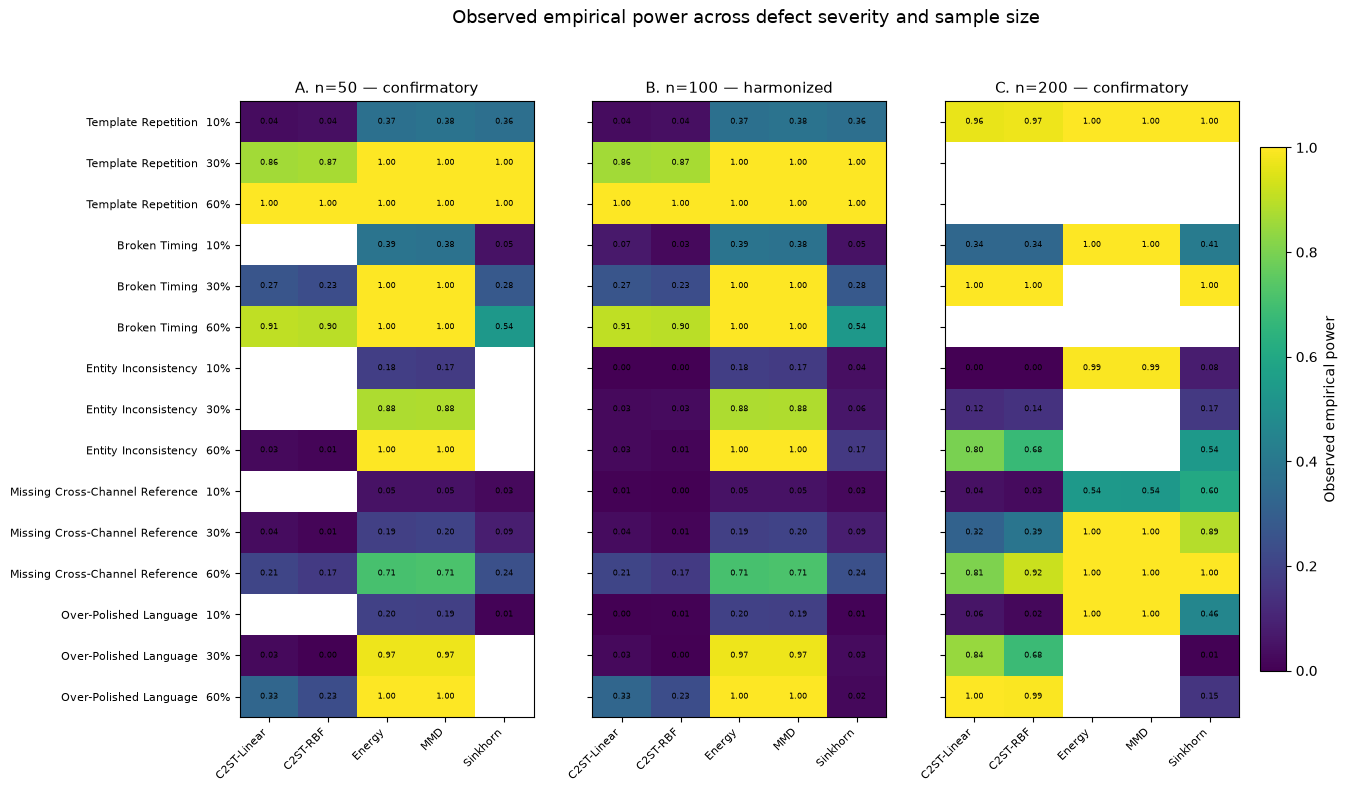

Saved: /Users/jessica/fidelity-metric-lab/paper/figures/Figure_1_observed_power.png


In [2]:
# --- Figure 1: observed power, N=50/100/200 ---

p_final = ROOT/"results/week12/final_observed_analysis/final_observed_power_wilson.csv"
p_h100  = ROOT/"results/week12/harmonized_analysis/combined_power_cells_harmonized_n100.csv"

a = pd.read_csv(p_final)
h = pd.read_csv(p_h100)

def standardize_power(df, forced_n=None):
    out = pd.DataFrame({
        "scenario": df[col(df,"scenario","defect","failure_mode")].astype(str),
        "prevalence": df[col(df,"prevalence","repetition","severity","defect_prevalence")].map(norm_prev),
        "test": df[col(df,"test","test_name","method")].map(norm_test),
        "power": pd.to_numeric(df[col(df,"power","observed_power","empirical_power")], errors="coerce"),
    })
    out["n"] = forced_n if forced_n is not None else pd.to_numeric(
        df[col(df,"n","sample_size","N")], errors="coerce"
    )
    return out

d = standardize_power(a)
d = pd.concat([d[d.n != 100], standardize_power(h, 100)], ignore_index=True)

scenario_order = [
    "Template Repetition",
    "Broken Timing",
    "Entity Inconsistency",
    "Missing Cross-Channel Reference",
    "Over-Polished Language",
]

# Match canonical labels without altering underlying results.
def canon_scenario(x):
    s = x.lower()
    if "template" in s: return "Template Repetition"
    if "broken" in s or "timing" in s: return "Broken Timing"
    if "entity" in s: return "Entity Inconsistency"
    if "missing" in s or "cross" in s: return "Missing Cross-Channel Reference"
    if "polish" in s: return "Over-Polished Language"
    return x

d["scenario"] = d["scenario"].map(canon_scenario)
d = d[d.prevalence.isin(PREV_ORDER)]

rows = pd.MultiIndex.from_product(
    [scenario_order, PREV_ORDER], names=["scenario","prevalence"]
)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 8), sharey=True)

im = None
for ax, N, title in zip(
    axes,
    [50,100,200],
    ["A. n=50 — confirmatory",
     "B. n=100 — harmonized",
     "C. n=200 — confirmatory"]
):
    x = (d[d.n == N]
         .pivot_table(index=["scenario","prevalence"],
                      columns="test", values="power", aggfunc="first")
         .reindex(index=rows, columns=TEST_ORDER))

    arr = np.ma.masked_invalid(x.to_numpy(float))
    im = ax.imshow(arr, vmin=0, vmax=1, aspect="auto")

    ax.set_title(title, fontsize=11)
    ax.set_xticks(range(len(TEST_ORDER)))
    ax.set_xticklabels(TEST_ORDER, rotation=45, ha="right", fontsize=8)

    if ax is axes[0]:
        ax.set_yticks(range(len(rows)))
        ax.set_yticklabels(
            [f"{s}  {int(p*100)}%" for s,p in rows], fontsize=8
        )

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if not arr.mask[i,j]:
                ax.text(j, i, f"{arr[i,j]:.2f}",
                        ha="center", va="center", fontsize=6)

fig.colorbar(im, ax=axes, label="Observed empirical power",
             fraction=.025, pad=.02)
fig.suptitle("Observed empirical power across defect severity and sample size",
             y=.995, fontsize=13)
plt.savefig(FIG/"Figure_1_observed_power.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", FIG/"Figure_1_observed_power.png")

### Table 1 — paired contrasts

In [3]:
# --- Table 1: selected paired contrasts ---

src = ROOT/"results/week12/final_observed_analysis/selected_paired_contrasts.csv"
t = pd.read_csv(src)

# Preserve numerical values exactly; only clean column presentation/order.
preferred = [
    "scenario","prevalence","n",
    "test_a","test_b",
    "power_a","power_b","power_difference",
    "n01","n10",
    "p_value","p_adjusted"
]

lookup = {re.sub(r"[^a-z0-9]","",c.lower()): c for c in t.columns}
keep = []
for x in preferred:
    k = re.sub(r"[^a-z0-9]","",x.lower())
    if k in lookup:
        keep.append(lookup[k])

out = t[keep] if keep else t.copy()

out.to_csv(TAB/"Table_1_paired_contrasts.csv", index=False)

display(out)
print("Saved:", TAB/"Table_1_paired_contrasts.csv")

,scenario,N,test_a,test_b,p_value
0,Entity Inconsistency,200,C2ST-Linear,MMD,2.489206e-60
1,Entity Inconsistency,200,C2ST-RBF,MMD,2.489206e-60
2,Over-Polished Language,200,C2ST-Linear,MMD,2.548947e-57
3,Broken Timing,200,C2ST-Linear,MMD,1.836710e-40


Saved: /Users/jessica/fidelity-metric-lab/paper/tables/Table_1_paired_contrasts.csv


### Figure 2 — Encoder robustness: MiniLM vs BGE

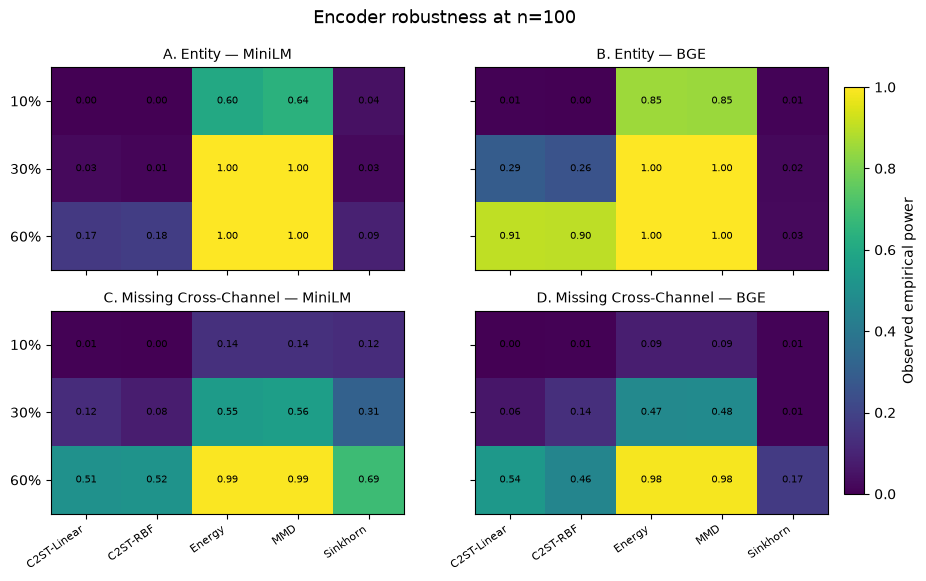

Source: /Users/jessica/fidelity-metric-lab/results/week12/final_reporting/bge_vs_minilm_n100.csv
Saved: /Users/jessica/fidelity-metric-lab/paper/figures/Figure_2_encoder_robustness.png


In [4]:
# --- Figure 2: MiniLM vs BGE robustness ---

paths = [
    ROOT/"results/week12/final_reporting/bge_vs_minilm_n100.csv",
    ROOT/"results/week13/bge_confirmatory/analysis/bge_vs_minilm_n100.csv",
]
src = next(p for p in paths if p.exists())
b = pd.read_csv(src)

scenario_c = col(b,"scenario","defect","failure_mode")
prev_c     = col(b,"prevalence","repetition","severity")
test_c     = col(b,"test","test_name","method")

base = pd.DataFrame({
    "scenario": b[scenario_c].astype(str),
    "prevalence": b[prev_c].map(norm_prev),
    "test": b[test_c].map(norm_test),
})

# Supports either wide MiniLM/BGE columns OR long encoder/power format.
try:
    minilm_c = col(b,"minilm_power","power_minilm","minilm")
    bge_c    = col(b,"bge_power","power_bge","bge")
    q = pd.concat([
        base.assign(encoder="MiniLM",
                    power=pd.to_numeric(b[minilm_c], errors="coerce")),
        base.assign(encoder="BGE",
                    power=pd.to_numeric(b[bge_c], errors="coerce"))
    ])
except KeyError:
    enc_c   = col(b,"encoder","embedding","representation")
    power_c = col(b,"power","observed_power","empirical_power")
    q = base.assign(
        encoder=b[enc_c].astype(str),
        power=pd.to_numeric(b[power_c], errors="coerce")
    )
    q["encoder"] = np.where(
        q.encoder.str.lower().str.contains("bge"), "BGE", "MiniLM"
    )

def short_scenario(x):
    s=x.lower()
    if "entity" in s: return "Entity"
    if "missing" in s or "cross" in s: return "Missing Cross-Channel"
    return x

q["scenario"] = q.scenario.map(short_scenario)

panels = [
    ("Entity","MiniLM","A. Entity — MiniLM"),
    ("Entity","BGE","B. Entity — BGE"),
    ("Missing Cross-Channel","MiniLM","C. Missing Cross-Channel — MiniLM"),
    ("Missing Cross-Channel","BGE","D. Missing Cross-Channel — BGE"),
]

fig, axes = plt.subplots(2,2,figsize=(10.5,5.8),
                         sharex=True, sharey=True)

for ax,(sc,enc,title) in zip(axes.flat, panels):
    z = (q[(q.scenario==sc)&(q.encoder==enc)]
         .pivot_table(index="prevalence",columns="test",
                      values="power",aggfunc="first")
         .reindex(index=PREV_ORDER, columns=TEST_ORDER))

    arr=np.ma.masked_invalid(z.to_numpy(float))
    im=ax.imshow(arr,vmin=0,vmax=1,aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(5))
    ax.set_xticklabels(TEST_ORDER,rotation=35,ha="right",fontsize=8)
    ax.set_yticks(range(3))
    ax.set_yticklabels(["10%","30%","60%"])

    for i in range(3):
        for j in range(5):
            if not arr.mask[i,j]:
                ax.text(j,i,f"{arr[i,j]:.2f}",
                        ha="center",va="center",fontsize=7)

fig.colorbar(im,ax=axes,label="Observed empirical power",
             fraction=.025,pad=.02)
fig.suptitle("Encoder robustness at n=100", fontsize=13)
plt.savefig(FIG/"Figure_2_encoder_robustness.png",
            dpi=300,bbox_inches="tight")
plt.show()

print("Source:", src)
print("Saved:", FIG/"Figure_2_encoder_robustness.png")

### Figure 3 — Diagnostic mechanisms

In [5]:
# --- Figure 3: diagnostic mechanisms ---

# ---------- A. Sinkhorn observed - permutation-null ----------
gap_files = sorted((ROOT/"results/week7").glob("*sinkhorn_null_gap.csv"))
assert gap_files, "No *_sinkhorn_null_gap.csv files found."

parts = []
for f in gap_files:
    x = pd.read_csv(f)

    pc = col(x,"prevalence","repetition","severity")
    try:
        gc = col(x,"gap","null_gap","observed_minus_null",
                 "sinkhorn_null_gap","observed_minus_null_mean")
        gap = pd.to_numeric(x[gc],errors="coerce")
    except KeyError:
        oc = col(x,"observed","observed_sinkhorn","statistic")
        nc = col(x,"null_mean","mean_null","permutation_null_mean")
        gap = (pd.to_numeric(x[oc],errors="coerce")
               - pd.to_numeric(x[nc],errors="coerce"))

    name = f.stem.lower()
    if "template" in name: sc="Template"
    elif "broken" in name or "timing" in name: sc="Broken Timing"
    elif "entity" in name: sc="Entity"
    elif "missing" in name or "reference" in name: sc="Missing Cross-Channel"
    elif "polish" in name: sc="Over-Polished"
    else: sc=f.stem

    parts.append(pd.DataFrame({
        "scenario":sc,
        "prevalence":x[pc].map(norm_prev),
        "gap":gap
    }))

sg = pd.concat(parts,ignore_index=True)
sg = (sg.groupby(["scenario","prevalence"],as_index=False)
        ["gap"].mean())

# ---------- B. Template Improved Precision / Recall ----------
ipr_candidates = [
    ROOT/"results/week7/ipr_five_defects_compact.csv",
    ROOT/"results/week7/ipr_five_defects_summary.csv",
    ROOT/"results/week7/ipr_repetition_stress.csv",
    ROOT/"results/week7/ipr_template_reference_comparison.csv",
]

ipr_src = next((p for p in ipr_candidates if p.exists()), None)

if ipr_src is None:
    hits = list((ROOT/"results").rglob("ipr_*summary.csv")) \
         + list((ROOT/"results").rglob("ipr_repetition_stress.csv"))
    ipr_src = hits[0]

r = pd.read_csv(ipr_src)

# Keep Template Repetition only if file contains multiple defects.
try:
    sc = col(r,"scenario","defect","failure_mode")
    r = r[r[sc].astype(str).str.lower().str.contains("template|repetition")]
except KeyError:
    pass

pc = col(r,"prevalence","repetition","severity")
pr = col(r,"improved_precision","precision","ipr_precision")
rc = col(r,"improved_recall","recall","ipr_recall")

ipr = pd.DataFrame({
    "prevalence":r[pc].map(norm_prev),
    "precision":pd.to_numeric(r[pr],errors="coerce"),
    "recall":pd.to_numeric(r[rc],errors="coerce"),
}).groupby("prevalence",as_index=False).mean()

# ---------- plot ----------
fig,axes=plt.subplots(1,2,figsize=(11,4.3))

for sc,g in sg.groupby("scenario"):
    g=g.sort_values("prevalence")
    axes[0].plot(g.prevalence*100,g.gap,marker="o",label=sc)

axes[0].axhline(0,lw=.8)
axes[0].set_xticks([10,30,60])
axes[0].set_xlabel("Defect prevalence (%)")
axes[0].set_ylabel("Observed Sinkhorn − mean permutation-null")
axes[0].set_title("A. Sinkhorn separation from paired null")
axes[0].legend(fontsize=7,frameon=False)

ipr=ipr.sort_values("prevalence")
axes[1].plot(ipr.prevalence*100,ipr.precision,
             marker="o",label="Improved Precision")
axes[1].plot(ipr.prevalence*100,ipr.recall,
             marker="o",label="Improved Recall")
axes[1].set_xticks([10,30,60])
axes[1].set_ylim(0,1)
axes[1].set_xlabel("Template Repetition prevalence (%)")
axes[1].set_ylabel("Score")
axes[1].set_title("B. Template Repetition support behavior")
axes[1].legend(frameon=False)

fig.suptitle("Diagnostic mechanisms behind metric disagreement",
             fontsize=13)
plt.tight_layout()
plt.savefig(FIG/"Figure_3_diagnostic_mechanisms.png",
            dpi=300,bbox_inches="tight")
plt.show()

print("IPR source:", ipr_src)
print("Saved:", FIG/"Figure_3_diagnostic_mechanisms.png")

KeyError: "None of ('observed', 'observed_sinkhorn', 'statistic') found.\nColumns: ['severity', 'mean_statistic', 'mean_null', 'mean_obs_minus_null', 'std_obs_minus_null', 'power']"

In [ ]:
# final check
outputs = [
    FIG/"Figure_1_observed_power.png",
    TAB/"Table_1_paired_contrasts.csv",
    FIG/"Figure_2_encoder_robustness.png",
    FIG/"Figure_3_diagnostic_mechanisms.png",
]

for p in outputs:
    print("✓" if p.exists() else "✗", p.relative_to(ROOT))

print(f"\nElapsed: {time.perf_counter()-T0:.1f} s")